# 11. Séries em logaritmo: estacionariedade e correlação com o crédito sem o Bradesco

Primeiro passo da modelagem econométrica (seção 6.1 do artigo). O notebook 10 decidiu que o crédito dos modelos é o crédito dos demais bancos (`credito_ex_bradesco`, jan/2015 a dez/2024). Aqui se refaz, com essa série, o que os notebooks 07 e 09 fizeram com `credito_total`: teste ADF e correlação em nível e em primeira diferença.

**Escolhas metodológicas**

- **Logaritmos.** As variações em log são variações percentuais, e a sazonalidade da exportação é multiplicativa (notebook 08).
- **Amostras.** Câmbio, exportação e importação: 132 meses (jan/2015 a dez/2025). Quando o crédito entra: 120 meses (jan/2015 a dez/2024).
- **ADF:** constante e defasagens pelo AIC, como no 07.
- **Correlação:** Pearson, 6 pares, limiar de Bonferroni p < 0,05/6 ≈ 0,0083, como no 09.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')

# lê os arquivos da pasta local do repositório quando ela existe; senão, direto do GitHub
RAIZ = 'https://raw.githubusercontent.com/vicleme/port-of-santos-credit-fx/refs/heads/main/'

def ler(caminho, **kw):
    local = os.path.join('..', caminho)
    return pd.read_csv(local if os.path.exists(local) else RAIZ + caminho, **kw)

def fmt(x, casas=2):
    """número com vírgula decimal"""
    return f'{x:.{casas}f}'.replace('.', ',')

def fmtp(p):
    """p-valor no estilo do artigo"""
    return '<0,0001' if p < 0.0001 else fmt(p, 4)

from itertools import combinations
from scipy import stats
from statsmodels.tsa.stattools import adfuller

painel = ler('data/processed/painel_modelagem_2015_2025.csv')
painel['data'] = pd.to_datetime(dict(year=painel['ano'], month=painel['mes'], day=1))
painel = painel.set_index('data')

logs = pd.DataFrame({
    'cambio_venda': np.log(painel['cambio_venda']),
    'credito_ex_bradesco': np.log(painel['credito_ex_bradesco']),
    'exportação_fob': np.log(painel['exportação_fob']),
    'importação_fob': np.log(painel['importação_fob']),
})
amostra120 = logs.dropna()
print(f'painel completo: {len(logs)} meses | amostra com crédito: {len(amostra120)} meses '
      f'({amostra120.index.min():%Y-%m} a {amostra120.index.max():%Y-%m})')

painel completo: 132 meses | amostra com crédito: 120 meses (2015-01 a 2024-12)


## 1. Teste ADF nas séries em log

Hipótese nula: raiz unitária (a série não volta a um patamar). Rejeitar (p < 0,05) indica série estacionária. Cada série é testada em nível e em primeira diferença; I(1) quer dizer não estacionária em nível e estacionária em Δ.

In [2]:
def adf(s):
    est, pv, lag, *_ = adfuller(s.dropna(), regression='c', autolag='AIC')
    return est, pv, lag

linhas = []
for nome in logs.columns:
    s = logs[nome].dropna()
    en, pn, ln = adf(s)
    ed, pd_, ld = adf(s.diff())
    classe = 'I(1)' if (pn >= 0.05 and pd_ < 0.05) else ('I(0)' if pn < 0.05 else 'indefinida')
    linhas.append({'série (log)': nome, 'meses': len(s), 'estatística (nível)': en, 'p (nível)': pn, 'defasagens': ln,
                   'estatística (Δ)': ed, 'p (Δ)': pd_, 'classificação': classe})
tabela3 = pd.DataFrame(linhas)
display(tabela3.round(4))

,série (log),meses,estatística (nível),p (nível),defasagens,estatística (Δ),p (Δ),classificação
0,cambio_venda,132,-2.0529,0.2639,0,-11.5172,0.0000,I(1)
1,credito_ex_bradesco,120,0.5705,0.9869,1,-8.3536,0.0000,I(1)
2,exportação_fob,132,-0.0639,0.9529,13,-4.2009,0.0007,I(1)
3,importação_fob,132,-1.5646,0.5013,12,-3.6700,0.0046,I(1)


As quatro séries são I(1). O `credito_total` aparecia como I(0) no `07` (p = 0,03) só por efeito do degrau de agosto/2019; sem o Bradesco, o crédito se comporta como as demais séries. Isso resolve a ressalva que o `07` deixou em aberto.

**Cuidado com a leitura das defasagens.** Exportação e importação em log escolhem 11 a 13 defasagens pelo AIC. Com 132 meses e sazonalidade anual, isso é esperado (o ADF usa as defasagens para absorver o padrão sazonal), mas consome graus de liberdade. O veredito depende do critério? Conferência com AIC e BIC (o BIC penaliza mais as defasagens):

In [3]:
linhas = []
for nome in logs.columns:
    s = logs[nome].dropna()
    for crit in ['aic', 'bic']:
        est, pv, lag, *_ = adfuller(s, regression='c', autolag=crit)
        estd, pvd, lagd, *_ = adfuller(s.diff().dropna(), regression='c', autolag=crit)
        linhas.append({'série (log)': nome, 'critério': crit.upper(), 'p (nível)': pv, 'defasagens (nível)': lag, 'p (Δ)': pvd})
display(pd.DataFrame(linhas).round(4))

,série (log),critério,p (nível),defasagens (nível),p (Δ)
0,cambio_venda,AIC,0.2639,0,0.0000
1,cambio_venda,BIC,0.2639,0,0.0000
2,credito_ex_bradesco,AIC,0.9869,1,0.0000
3,credito_ex_bradesco,BIC,0.9897,0,0.0000
4,exportação_fob,AIC,0.9529,13,0.0007
5,exportação_fob,BIC,0.9418,11,0.0000
6,importação_fob,AIC,0.5013,12,0.0046
7,importação_fob,BIC,0.3328,3,0.0046


O veredito não muda: nas quatro séries, o p em nível fica muito acima de 0,05 e o p em Δ fica abaixo, com AIC ou com BIC.

## 2. Correlação em nível e em primeira diferença

Em nível, séries I(1) com tendência aparecem correlacionadas mesmo sem relação real. Em primeira diferença, mede-se se as **variações percentuais mensais** se movem juntas.

In [4]:
dif = amostra120.diff().dropna()
corr_niv = amostra120.corr()
corr_dif = dif.corr()
limiar = 0.05 / 6

linhas = []
for a, b in combinations(amostra120.columns, 2):
    r, pv = stats.pearsonr(dif[a], dif[b])
    rho, pv_s = stats.spearmanr(dif[a], dif[b])
    linhas.append({'par': f'{a} × {b}', 'r (nível)': corr_niv.loc[a, b], 'r (Δ)': r, 'p (Δ)': pv,
                   'ρ Spearman (Δ)': rho, 'p Spearman': pv_s, 'passa Bonferroni?': 'Sim' if pv < limiar else 'Não'})
tabela_corr = pd.DataFrame(linhas)
display(tabela_corr.round(4))
print(f'observações: {len(amostra120)} em nível, {len(dif)} em Δ | limiar de Bonferroni: {limiar:.4f}')

,par,r (nível),r (Δ),p (Δ),ρ Spearman (Δ),p Spearman,passa Bonferroni?
0,cambio_venda × credito_ex_bradesco,0.7406,-0.0395,0.6698,0.0132,0.8866,Não
1,cambio_venda × exportação_fob,0.6549,0.0851,0.3573,0.0272,0.7686,Não
2,cambio_venda × importação_fob,0.5941,-0.0710,0.4432,-0.0684,0.4600,Não
3,credito_ex_bradesco × exportação_fob,0.7992,-0.0121,0.8958,-0.0805,0.3839,Não
4,credito_ex_bradesco × importação_fob,0.6939,0.1557,0.0910,0.0144,0.8761,Não
5,exportação_fob × importação_fob,0.7911,0.2454,0.0072,0.2366,0.0096,Sim


observações: 120 em nível, 119 em Δ | limiar de Bonferroni: 0.0083


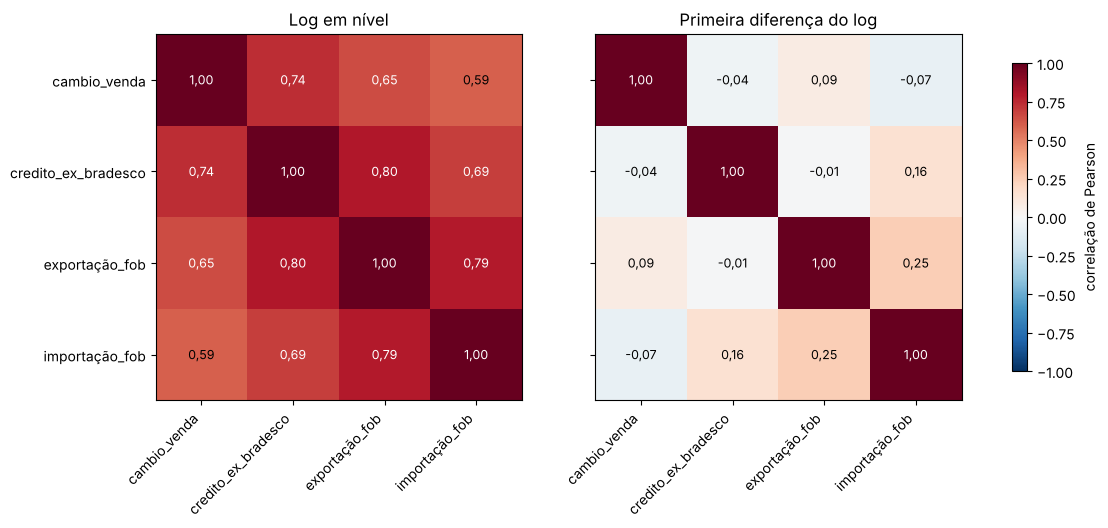

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
nomes = list(amostra120.columns)
for ax, corr, titulo in [(axes[0], corr_niv, 'Log em nível'), (axes[1], corr_dif, 'Primeira diferença do log')]:
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
    ax.set_xticks(range(len(nomes))); ax.set_yticks(range(len(nomes)))
    ax.set_xticklabels(nomes, rotation=45, ha='right')
    if ax is axes[0]: ax.set_yticklabels(nomes)
    for i in range(len(nomes)):
        for j in range(len(nomes)):
            v = corr.iloc[i, j]
            ax.text(j, i, fmt(v), ha='center', va='center', color='white' if abs(v) > 0.6 else 'black', fontsize=9)
    ax.set_title(titulo)
fig.colorbar(im, ax=axes, shrink=0.8, label='correlação de Pearson')
plt.show()

In [6]:
niv_abs = [abs(corr_niv.loc[a, b]) for a, b in combinations(nomes, 2)]
dif_vals = [corr_dif.loc[a, b] for a, b in combinations(nomes, 2)]
print(f'correlação em nível (log): de {fmt(min(niv_abs))} a {fmt(max(niv_abs))}')
unico = tabela_corr[tabela_corr['passa Bonferroni?'] == 'Sim']['par'].tolist()
restantes = tabela_corr[tabela_corr['passa Bonferroni?'] == 'Não']['r (Δ)']
print(f'correlação em Δ nos pares que não passam em Bonferroni: de {fmt(restantes.min())} a {fmt(restantes.max())}')
print('pares que passam no corte de Bonferroni:', unico)

correlação em nível (log): de 0,59 a 0,80
correlação em Δ nos pares que não passam em Bonferroni: de -0,07 a 0,16
pares que passam no corte de Bonferroni: ['exportação_fob × importação_fob']


## Conclusões

1. Em log, as quatro séries são I(1), inclusive o crédito sem o Bradesco.
2. As correlações em nível são altas (de 0,59 a 0,80) e quase todas desaparecem em Δ (de -0,07 a 0,16, sem passar em Bonferroni). O degrau do crédito **não escondia** uma relação com câmbio ou carga.
3. O único par que passa em Bonferroni é exportação × importação (r = 0,25; p = 0,0072 contra o limiar de 0,0083), por pouco e menor que na versão sem logaritmos (r = 0,36, notebook 09). No Spearman o mesmo par tem p = 0,0096, **acima** do limiar, o que reforça que o resultado é frágil.
4. Como as séries são todas I(1), a pergunta que sobra é se há **cointegração**, que a diferenciação apagaria. É o notebook 12.